# Testing the cylindrical kernel on benchmark functions

In [1]:
%matplotlib inline
from glob import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(rc={"xtick.labelsize": 12, "ytick.labelsize": 12})
sns.set_style("ticks", {"xtick.major.size": 8, "ytick.major.size": 8})

In [2]:
def make_plot(dfs, field, ax=None, yscale='linear', index=None, with_return=False, title=None, ylabel=None):
    if ax is None:
        f, ax = plt.subplots(1)
    res = {}
    print(field)
    for name, df in dfs.items():
        if index is None:
            index = df[0].index - 1
        v = aggregate(df, field)
        v_mean = np.mean(v, 0)[index]
        v_std = np.std(v, 0)[index]
        ax.plot(index, v_mean, label=name)
        ax.fill_between(index, v_mean if yscale == 'log' else v_mean - v_std, v_mean + v_std, alpha=0.2)
        res[name] = (v_mean, v_std)
        print(u'{0}: last={1:.3f}\u00B1{2:.3f}'.format(name, v_mean[-1], v_std[-1]))
    ax.legend()
    ax.grid()
    if title:
        ax.set_title(title)
    ax.set_ylabel(field if ylabel is None else ylabel, fontsize=16, fontweight='bold')
    ax.set_xlabel('Acquisitions', fontsize=16, fontweight='bold')
    ax.set_yscale(yscale)
    if with_return:
        return ax, res

aggregate = lambda dfs, field: np.stack([df[field] for df in dfs])
s2a = lambda s: np.array([float(ss) for ss in s.replace('[', '').replace(']', '').replace('\n', '').split(' ') if ss])
str_to_array = lambda s: np.stack([s2a(ss)for ss in s])

def make_hist(dict_array, colors=['k', 'r'], bins=50, ylim=None, title=None, ax=None, with_return=False):
    if ax is None:
        f, ax = plt.subplots(1)
    for i, (name, array) in enumerate(dict_array.items()):
        ax.hist(array, bins=bins, color=colors[i] if i < len(colors) else None, density=True, label=name)
        print(f"{name}: avg={np.mean(array):.3e}")
    if ylim:
        ax.set_ylim([0, 8])
    if title:
        ax.set_title(title, fontsize=16, fontweight='bold')
    ax.legend()
    if with_return:
        return ax

## Number of initial points: 2 vs 20
Results show that it is better to take fewer initial points when using the cylindrical kernel.

Initial points with large radius will affect the exploration. Acquisitions are more likely to be near the origin.
This effect is clearly visible in Rosenbrock 20D.

The posterior predictive distributions show that the kernel can be unstable. Internally, the method can yield negative variances, which are then clipped to a small positive value (1e-12). A related problem is that in order to ensure positive definiteness of the gram matrix, the implementation doesn't define an upper bound for the jitter. It keeps increasing the jitter until the gram matrix is positive definite. In some cases, the jitter can be as high as 1e2 and variances as low as -1e3. This can be problematic in BOLFI because we rely on these distributions, even more so than standard BO

### Rosenbrock 20D (5 runs)
Global minimum: 0

Reported minimum: 47.87±33.94

In [3]:
rosenbrock_d20 = glob('data/rosenbrock_D20*/log*_sphere_warping_origin.csv')
dfs = {'.'.join(log.split('_')[2:4]): pd.read_csv(log, index_col='iter') for log in rosenbrock_d20}
df1 = [v for k, v in dfs.items() if '2.' in k]
df2 = [v for k, v in dfs.items() if '20.' in k]
df_rosenbrock20d = {'init_2': df1, 'init_20': df2}

curr_min
init_2: last=41.847±31.208
init_20: last=7956.504±365.948


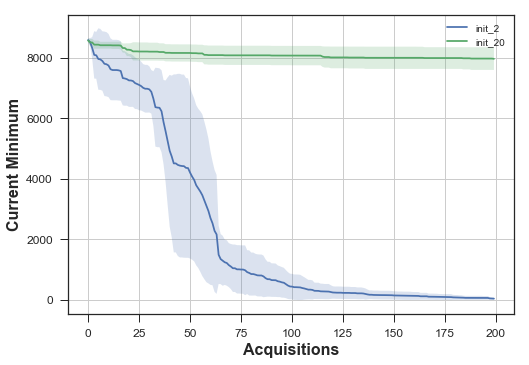

In [4]:
make_plot(df_rosenbrock20d, 'curr_min', ylabel='Current Minimum')

pred_mean
init_2: last=46.739±43.366
init_20: last=5551.434±1386.309
pred_std
init_2: last=28.960±17.984
init_20: last=2056.927±785.975


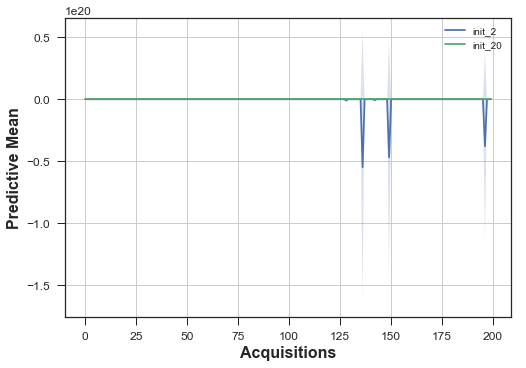

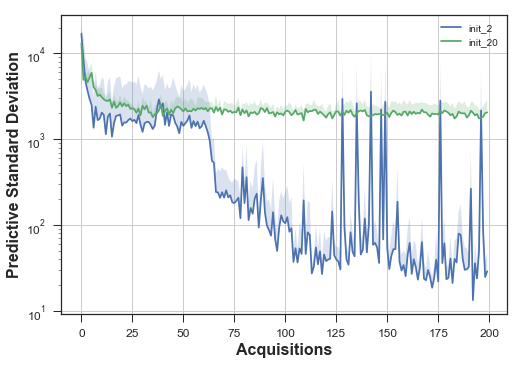

In [5]:
make_plot(df_rosenbrock20d, 'pred_mean', ylabel='Predictive Mean')
make_plot(df_rosenbrock20d, 'pred_std', ylabel='Predictive Standard Deviation', yscale='log')

input_r
init_2: last=0.786±0.035
init_20: last=0.059±0.007


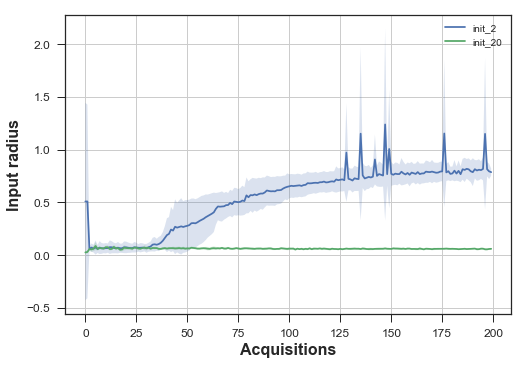

In [6]:
_, res_rosenbrock20d = make_plot(df_rosenbrock20d, 'input_r', with_return=True, ylabel='Input radius')

init_2: avg=5.392e-01
init_20: avg=6.032e-02


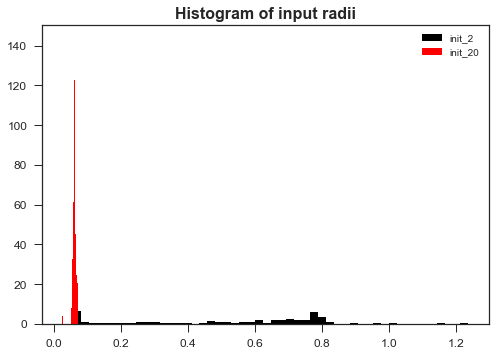

In [7]:
make_hist({'init_2': res_rosenbrock20d['init_2'][0], 'init_20': res_rosenbrock20d['init_20'][0]},
          title='Histogram of input radii')

#### Average input / minimizer

In [8]:
print("Input")
for name in ['init_2', 'init_20']:
    mean = np.mean(np.concatenate([str_to_array(df['input'].values) for df in df_rosenbrock20d[name]]), 0)
    print("{}: r={}\n{}".format(name, np.linalg.norm(mean), mean))
print("\nMinimizer")
for name in ['init_2', 'init_20']:
    min_loc = aggregate(df_rosenbrock20d[name], 'min_loc')
    mean = np.mean(str_to_array(min_loc[:, -1]), 0)
    print("{}: r={}\n{}".format(name, np.linalg.norm(mean), mean))   

Input
init_2: r=0.5028369128028466
[-0.11997068 -0.11533128 -0.12456635 -0.11770914 -0.12607837 -0.1175179
 -0.10961374 -0.11568924 -0.1174391  -0.11548906 -0.12881965 -0.11568657
 -0.11028091 -0.10803564 -0.11131816 -0.12167738 -0.11327041 -0.09857378
 -0.07451869  0.06659454]
init_20: r=0.01935654532461348
[ 0.00081461 -0.00586845  0.00087288 -0.00028121 -0.00402208  0.00526611
 -0.00162842 -0.00199564 -0.00027252 -0.00795999  0.00441243 -0.00380781
  0.00332254 -0.0076687  -0.00342906 -0.0048909  -0.00634863  0.00066379
 -0.00370173 -0.00555054]

Minimizer
init_2: r=0.7850045479767657
[-0.17982237 -0.18408891 -0.1889062  -0.18892715 -0.19741685 -0.17913488
 -0.179358   -0.18254784 -0.18578059 -0.18843293 -0.19363717 -0.1819466
 -0.17323251 -0.17896373 -0.17605934 -0.18612544 -0.18016824 -0.15753064
 -0.09459687  0.08688565]
init_20: r=0.03717046122456392
[  1.02575400e-04  -3.18003200e-03   4.73204120e-03   2.67626600e-05
  -7.32188536e-03   3.22085400e-04  -9.10306488e-03  -8.52201

### Levy 20D (5 runs)
Global minimum: 0

Reported minimum: 0.54±0.13

In [9]:
levy_d20 = glob('data/levy_D20*/log*')
dfs = {'.'.join(log.split('_')[2:4]): pd.read_csv(log, index_col='iter') for log in levy_d20}
df1 = [v for k, v in dfs.items() if '2.' in k]
df2 = [v for k, v in dfs.items() if '20.' in k]
df_levy20d = {'init_2': df1, 'init_20': df2}

curr_min
init_2: last=0.846±0.451
init_20: last=0.825±0.379


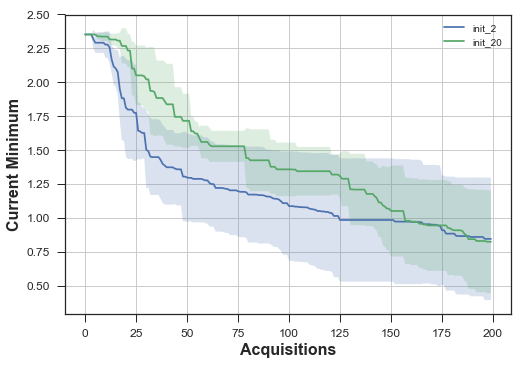

In [10]:
make_plot(df_levy20d, 'curr_min', ylabel='Current Minimum')

pred_mean
init_2: last=16.133±30.764
init_20: last=6.865±11.983
pred_std
init_2: last=5.979±11.542
init_20: last=5.054±9.021


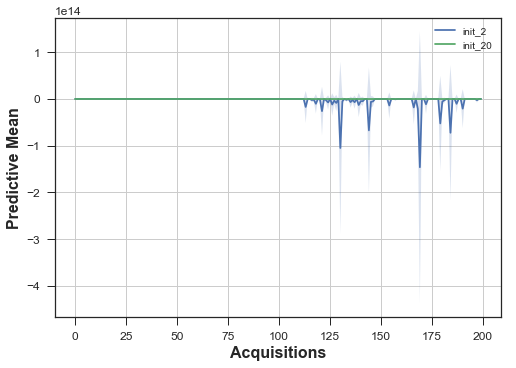

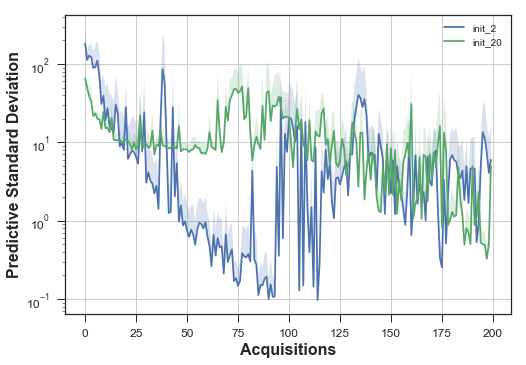

In [11]:
make_plot(df_levy20d, 'pred_mean', ylabel='Predictive Mean')
make_plot(df_levy20d, 'pred_std', ylabel='Predictive Standard Deviation', yscale='log')

input_r
init_2: last=0.762±0.853
init_20: last=0.483±0.349


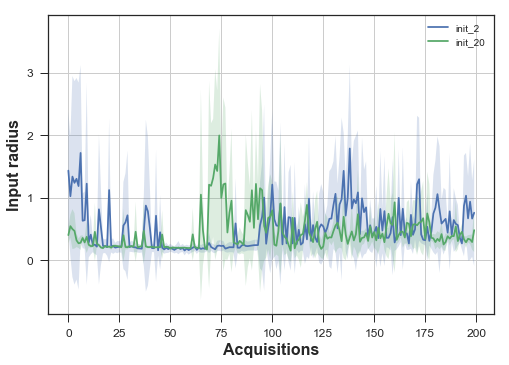

In [12]:
_, res_levy20d = make_plot(df_levy20d, 'input_r', with_return=True, ylabel='Input radius')

init_2: avg=5.162e-01
init_20: avg=4.449e-01


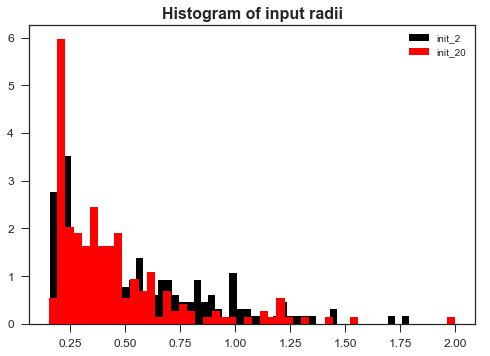

In [13]:
make_hist({'init_2': res_levy20d['init_2'][0], 'init_20': res_levy20d['init_20'][0]},
          title='Histogram of input radii')

#### Average input / minimizer

In [14]:
print("Input")
for name in ['init_2', 'init_20']:
    mean = np.mean(np.concatenate([str_to_array(df['input'].values) for df in df_levy20d[name]]), 0)
    print("{}: r={}\n{}".format(name, np.linalg.norm(mean), mean))
print("\nMinimizer")
for name in ['init_2', 'init_20']:
    min_loc = aggregate(df_levy20d[name], 'min_loc')
    mean = np.mean(str_to_array(min_loc[:, -1]), 0)
    print("{}: r={}\n{}".format(name, np.linalg.norm(mean), mean))    

Input
init_2: r=0.16854122771130742
[ 0.07196224  0.05278487  0.03831807  0.03416296  0.02716594  0.02694473
  0.03626041  0.01148662  0.01352553  0.04809811  0.04951524  0.01215281
  0.03687858  0.01763247  0.00566758  0.01547566  0.03663778  0.05840225
  0.04531062  0.03241326]
init_20: r=0.16207879247699905
[ 0.04884863  0.02936385  0.0195564   0.03060525  0.04145209  0.00982996
  0.02892641  0.04337682  0.05071342  0.02288911  0.03143582  0.03441266
  0.04926945  0.04235627  0.00987187  0.04454488  0.01377997  0.06057313
  0.03530913  0.02217258]

Minimizer
init_2: r=0.2830101909832952
[ 0.09633611  0.08686297  0.07603539  0.04529451  0.04947171  0.0594012
  0.06858975  0.05109423  0.03674122  0.06815554  0.07557621  0.04049496
  0.05567325  0.05722357  0.05899606  0.00942986  0.0479311   0.08366131
  0.05958351  0.07751029]
init_20: r=0.31456171138320105
[ 0.10131439  0.09140439  0.05885488  0.07720441  0.06692139  0.07193605
  0.06973817  0.05422944  0.06831161  0.06918495  0.093

### Hartmann6 18D (3 runs)
Global minimum: -3.3223

Reported minimum (20D): 3.30±0.02

In [15]:
hartmann6_d18 = glob('data/hartmann6_D18*/log*')
dfs = {'.'.join(log.split('_')[2:4]): pd.read_csv(log, index_col='iter') for log in hartmann6_d18}
df1 = [v for k, v in dfs.items() if '2.' in k]
df2 = [v for k, v in dfs.items() if '20.' in k]
df_hartmann6_d18 = {'init_2': df1, 'init_20': df2}

curr_min
init_2: last=-3.300±0.032
init_20: last=-3.072±0.045


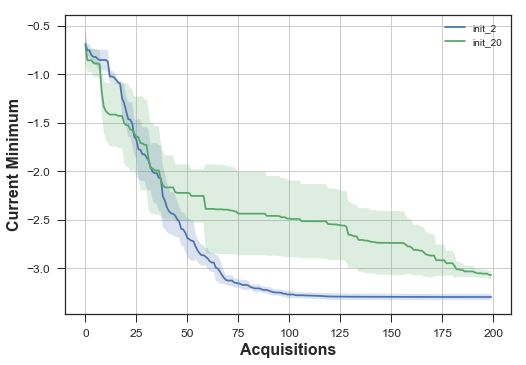

In [16]:
make_plot(df_hartmann6_d18, 'curr_min', ylabel='Current Minimum')

pred_mean
init_2: last=-3.309±0.040
init_20: last=-1.757±0.976
pred_std
init_2: last=0.015±0.009
init_20: last=0.844±0.552


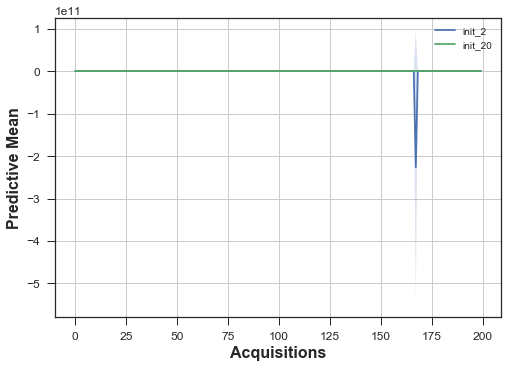

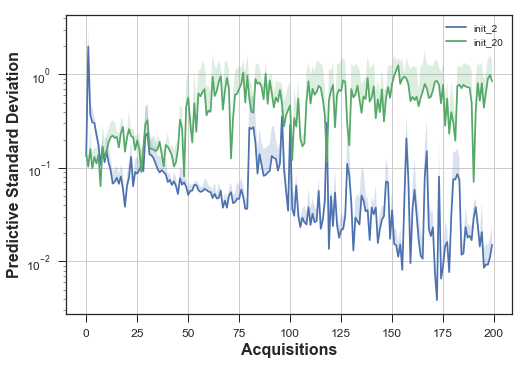

In [17]:
make_plot(df_hartmann6_d18, 'pred_mean', ylabel='Predictive Mean')
make_plot(df_hartmann6_d18, 'pred_std', ylabel='Predictive Standard Deviation', yscale='log')

input_r
init_2: last=2.001±0.030
init_20: last=2.073±0.236


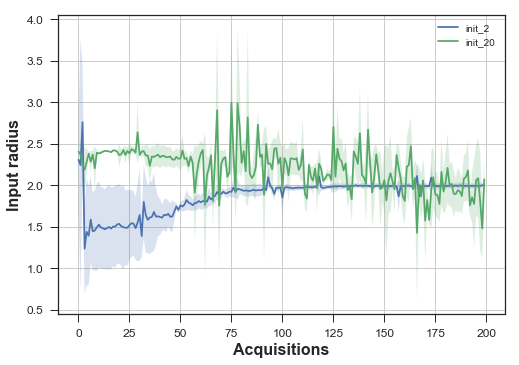

In [18]:
_, res_hartmann6_d18 = make_plot(df_hartmann6_d18, 'input_r', with_return=True, ylabel='Input radius')

init_2: avg=1.870e+00
init_20: avg=2.208e+00


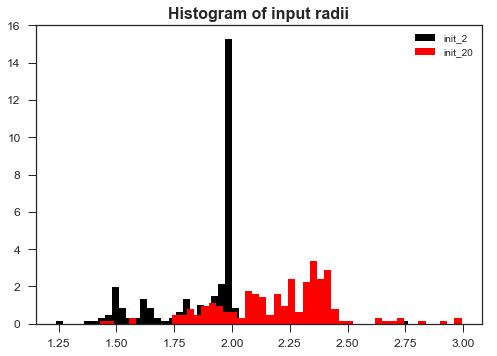

In [19]:
make_hist({'init_2': res_hartmann6_d18['init_2'][0], 'init_20': res_hartmann6_d18['init_20'][0]},
          title='Histogram of input radii')

#### Average input / minimizer

In [20]:
print("Input")
for name in ['init_2', 'init_20']:
    mean = np.mean(np.concatenate([str_to_array(df['input'].values) for df in df_hartmann6_d18[name]]), 0)
    print("{}: r={}\n{}".format(name, np.linalg.norm(mean), mean))
print("\nMinimizer")
for name in ['init_2', 'init_20']:
    min_loc = aggregate(df_hartmann6_d18[name], 'min_loc')
    mean = np.mean(str_to_array(min_loc[:, -1]), 0)
    print("{}: r={}\n{}".format(name, np.linalg.norm(mean), mean))      

Input
init_2: r=1.4387649955152295
[-0.39614519 -0.58392726 -0.08354482 -0.44769166 -0.32327034  0.28032162
 -0.3557606  -0.15418058 -0.05827774 -0.23669537 -0.20398301 -0.10000064
 -0.51130473 -0.54747365 -0.05502698 -0.39259085 -0.3544287   0.2763124 ]
init_20: r=1.3351602230850215
[-0.37445023 -0.45915602 -0.11299711 -0.30108313 -0.25881706  0.17265964
 -0.26647537  0.34811103  0.17362596 -0.14879628 -0.45480189 -0.25278051
 -0.18511848  0.45889947  0.39729456  0.10657395  0.1181243  -0.53681209]

Minimizer
init_2: r=1.7252155918804644
[-0.60201945 -0.69961945 -0.04913504 -0.45107529 -0.3816941   0.31449519
 -0.45566368 -0.21445255 -0.03925248 -0.24864511 -0.2321798  -0.09988342
 -0.60272236 -0.69970847 -0.04607309 -0.44537602 -0.37676013  0.31277434]
init_20: r=1.9449729850260056
[-0.66138433 -0.60570952 -0.10092335 -0.41764367 -0.41505369  0.2857331
 -0.30509596  0.23534776  0.36652051 -0.1201276  -0.56210672 -0.52991611
 -0.18521305  0.75688521  0.38729216  0.18083847  0.05089094

### Branin 20D (1 run)
Global minimum: 0.3979

Reported minimum: 0.50±0.12

In [21]:
branin_d20 = glob('data/branin_D20*/log*')
dfs = {'.'.join(log.split('_')[2:4]): pd.read_csv(log, index_col='iter') for log in branin_d20}
df1 = [v for k, v in dfs.items() if '2.' in k]
df2 = [v for k, v in dfs.items() if '20.' in k]
df_branin_d20 = {'init_2': df1, 'init_20': df2}

curr_min
init_2: last=0.542±0.000
init_20: last=3.909±0.000


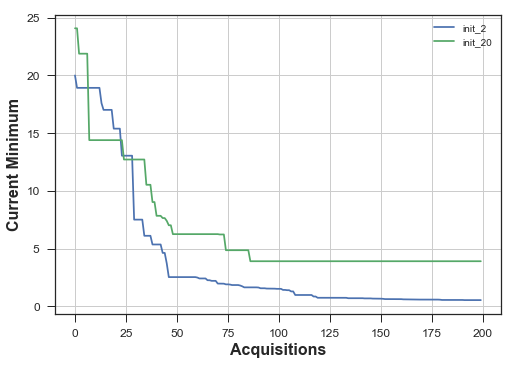

In [22]:
make_plot(df_branin_d20, 'curr_min', ylabel='Current Minimum')

pred_mean
init_2: last=0.559±0.000
init_20: last=7.685±0.000
pred_std
init_2: last=0.166±0.000
init_20: last=6.268±0.000


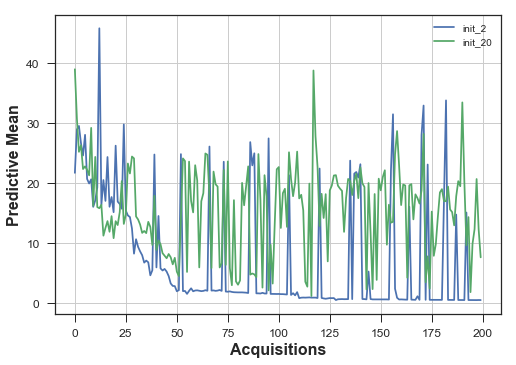

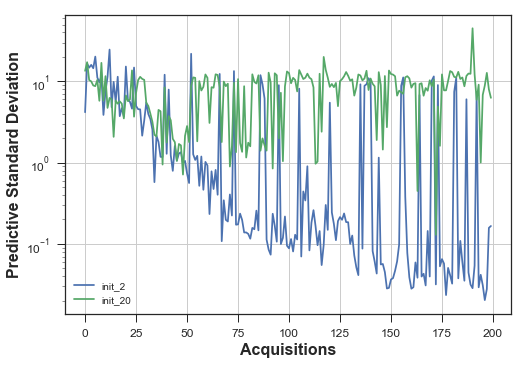

In [23]:
make_plot(df_branin_d20, 'pred_mean', ylabel='Predictive Mean')
make_plot(df_branin_d20, 'pred_std', ylabel='Predictive Standard Deviation', yscale='log')

input_r
init_2: last=2.458±0.000
init_20: last=0.834±0.000


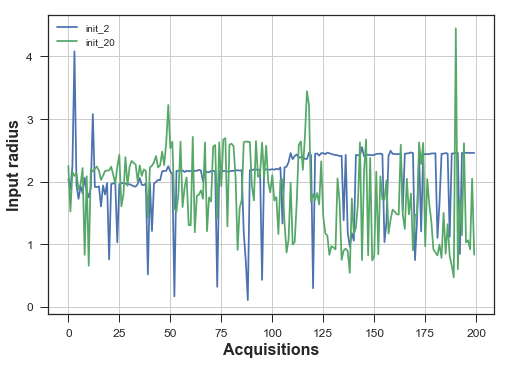

In [24]:
_, res_branin_d20 = make_plot(df_branin_d20, 'input_r', with_return=True, ylabel='Input radius')

init_2: avg=2.078e+00
init_20: avg=1.820e+00


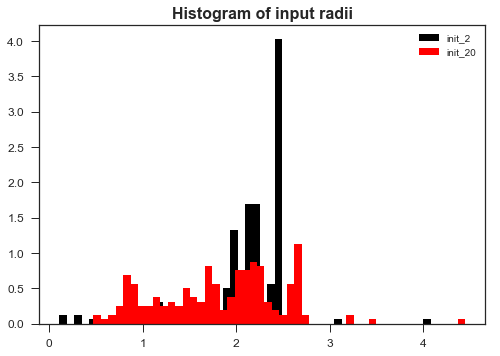

In [25]:
make_hist({'init_2': res_branin_d20['init_2'][0], 'init_20': res_branin_d20['init_20'][0]},
          title='Histogram of input radii')

In [26]:
print("Input")
for name in ['init_2', 'init_20']:
    mean = np.mean(np.concatenate([str_to_array(df['input'].values) for df in df_branin_d20[name]]), 0)
    print("{}: r={}\n{}".format(name, np.linalg.norm(mean), mean))
print("\nMinimizer")
for name in ['init_2', 'init_20']:
    min_loc = aggregate(df_branin_d20[name], 'min_loc')
    mean = np.mean(str_to_array(min_loc[:, -1]), 0)
    print("{}: r={}\n{}".format(name, np.linalg.norm(mean), mean))      

Input
init_2: r=1.889501922542562
[ 0.10030467 -0.52199412  0.09457842 -0.55340369 -0.59610139  0.33583655
  0.08613412 -0.46142438  0.75751999 -0.50873573  0.03301997 -0.44434776
  0.02826665 -0.41129591  0.05070499 -0.53353272  0.05414986 -0.39650702
 -0.6298533   0.48865405]
init_20: r=1.0266333816827198
[-0.27645     0.05632965 -0.30858749  0.13939489 -0.1871273  -0.02021149
  0.00959647 -0.32569093 -0.01445087 -0.41221329 -0.03124496 -0.22661687
  0.26277134 -0.29815912  0.29479353 -0.35538719 -0.28846903  0.04016731
 -0.10829055 -0.16722394]

Minimizer
init_2: r=2.459214851442108
[ 0.0714642  -0.6155745   0.09921014 -0.6839526  -0.72295344  0.49542528
  0.09226377 -0.6649606   0.9182935  -0.63251036  0.08579186 -0.67982423
  0.07778381 -0.7030921   0.07055053 -0.6595645   0.08583058 -0.6694781
 -0.7362305   0.5625153 ]
init_20: r=2.628872836539528
[-0.656775    0.4055633  -0.686666    0.4641696  -0.5710677  -0.10472161
  0.16667908 -0.9225088   0.06745474 -0.83364123  0.08219264 

## Sobol sequence: fixed vs random

It seems better to use a randomized sobol sequence during the minimization of the acquisition function (generation of candidates for random restarts). The acquisition function can be highly non-convex, therefore a fixed sobol sequence can slow down the process of finding the minimum.

### Rosenbrock 20D (5 runs)

In [27]:
rosenbrock_d20 = glob('data/rosenbrock_D20_2_*/log*.csv')
dfs = {log: pd.read_csv(log, index_col='iter') for log in rosenbrock_d20}
df1 = [v for k, v in dfs.items() if 'fix_sobol' in k]
df2 = [v for k, v in dfs.items() if 'fix_sobol' not in k]
df_rosenbrock_d20 = {'fixed': df1, 'random': df2}

curr_min
fixed: last=678.082±1201.944
random: last=41.847±31.208


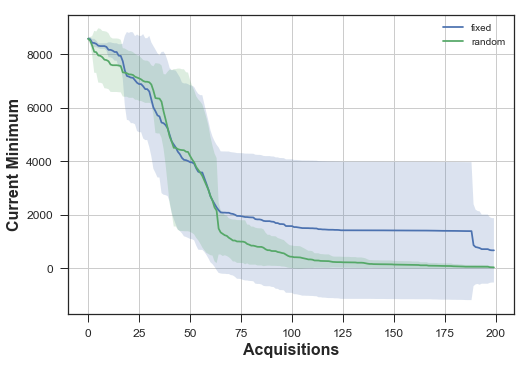

In [28]:
make_plot(df_rosenbrock_d20, 'curr_min', ylabel='Current Minimum')

input_r
fixed: last=0.616±0.269
random: last=0.786±0.035


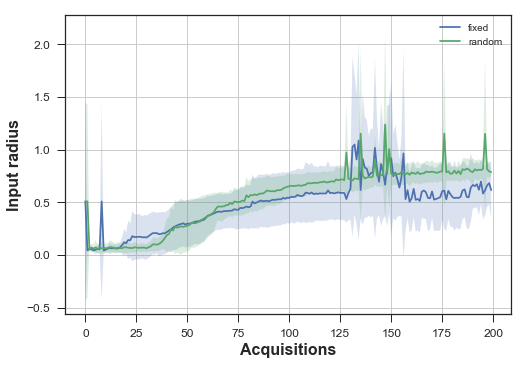

In [29]:
_, res_rosenbrock_d20 = make_plot(df_rosenbrock_d20, 'input_r', with_return=True, ylabel='Input radius')

fixed: avg=4.742e-01
random: avg=5.392e-01


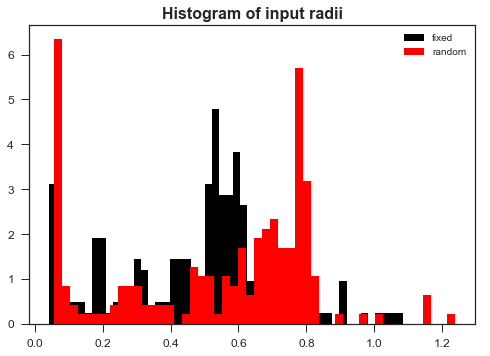

In [30]:
make_hist({'fixed': res_rosenbrock_d20['fixed'][0], 'random': res_rosenbrock_d20['random'][0]},
          title='Histogram of input radii')

### Levy 20D (5 runs)

In [31]:
levy_d20 = glob('data/levy_D20_2_*/log*.csv')
dfs = {log: pd.read_csv(log, index_col='iter') for log in levy_d20}
df1 = [v for k, v in dfs.items() if 'fix_sobol' in k]
df2 = [v for k, v in dfs.items() if 'fix_sobol' not in k]
df_levy_d20 = {'fixed': df1, 'random': df2}

curr_min
fixed: last=0.846±0.451
random: last=0.749±0.245
input_r
fixed: last=0.762±0.853
random: last=1.004±1.300
fixed: avg=5.162e-01
random: avg=3.931e-01


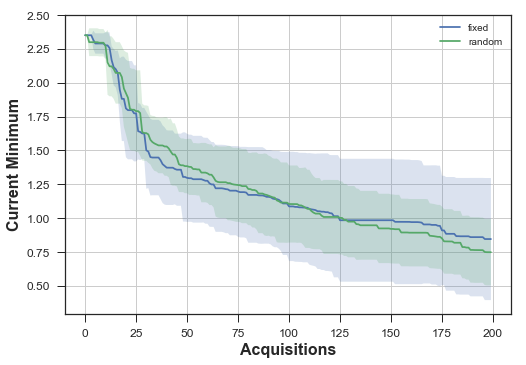

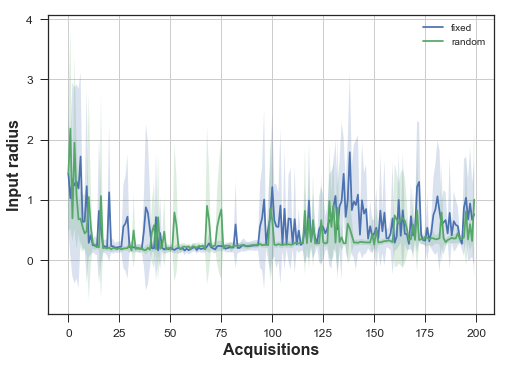

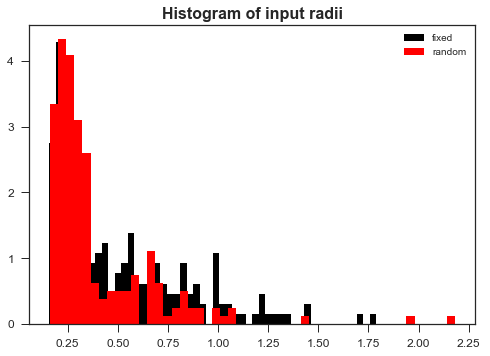

In [32]:
make_plot(df_levy_d20, 'curr_min', ylabel='Current Minimum')
_, res_levy_d20 = make_plot(df_levy_d20, 'input_r', with_return=True, ylabel='Input radius')
make_hist({'fixed': res_levy_d20['fixed'][0], 'random': res_levy_d20['random'][0]},
          title='Histogram of input radii')